# 🎭 Shakespeare GPT — RTX 4060 Trainer

A clean, trainable character-level GPT implemented with **PyTorch**, designed for:
- **GPU**: RTX 4060 (8 GB VRAM)
- **RAM**: 32 GB
- **Framework**: PyTorch + optional HuggingFace tokenizers

### What's inside
| Component | Detail |
|-----------|--------|
| Architecture | GPT-2 style decoder-only transformer |
| Tokenization | Character-level (simple) or BPE via HuggingFace |
| Training | Mixed precision (fp16), gradient accumulation, LR warmup |
| Logging | Live loss + perplexity curves via matplotlib |
| Inference | Temperature / top-k / top-p sampling |
| Checkpointing | Auto-save best model |

---

## 1. Install Dependencies

In [10]:
# Run once — comment out after first run
# !pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121 -q
# !pip install transformers datasets tiktoken matplotlib tqdm sentencepiece -q
# print('✅ Dependencies installed')

## 2. Imports & Device Setup

In [11]:
import os, math, time, json, random, pickle
from pathlib import Path
from dataclasses import dataclass, field
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from tqdm.auto import tqdm

# ── Device ──────────────────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print(f'✅ GPU : {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
    # Enable TF32 for faster matmuls on Ampere/Ada cards
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    print('⚠️  No GPU found — running on CPU (slow)')

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

✅ GPU : NVIDIA GeForce RTX 4060 Laptop GPU
   VRAM: 8.6 GB


## 3. Hyperparameters

Tuned for an RTX 4060 (8 GB VRAM). Adjust `n_layer`, `n_head`, `n_embd` to scale up/down.

In [12]:
@dataclass
class Config:
    # ── Model ────────────────────────────────────────────────────────────
    vocab_size: int    = 65        # set automatically after tokenizer build
    block_size: int    = 256       # context window (tokens)
    n_layer:    int    = 6         # transformer blocks
    n_head:     int    = 8         # attention heads (Bumped to 8)
    n_embd:     int    = 512       # embedding dimension (Bumped to 512)
    dropout:    float  = 0.1
    bias:       bool   = False     # no bias = slightly faster

# ── Training ─────────────────────────────────────────────────────────
    batch_size:        int   = 32     # 16 to stop VRAM spilling
    grad_accum_steps:  int   = 2      # 8 (8x8 = 64 effective batch)
    max_iters:         int   = 10000
    eval_interval:     int   = 500
    eval_iters:        int   = 50
    log_interval:      int   = 50

    # ── Optimiser ────────────────────────────────────────────────────────
    learning_rate: float = 5e-4    # Increased slightly for larger embedding table
    min_lr:        float = 5e-5    # cosine decay floor
    warmup_iters:  int   = 200
    weight_decay:  float = 1e-1
    beta1:         float = 0.9
    beta2:         float = 0.95
    grad_clip:     float = 1.0

    # ── Mixed precision ───────────────────────────────────────────────────
    use_amp:   bool = True         # fp16 — saves ~2× VRAM
    compile:   bool = False        # torch.compile (PyTorch ≥ 2.0, faster)

    # ── I/O ───────────────────────────────────────────────────────────────
    out_dir:       str  = 'checkpoints'
    data_file:     str  = 'wikitext2.txt'
    resume:        bool = False    # resume from latest checkpoint

cfg = Config()

# Rough VRAM estimate
approx_params = cfg.n_layer * (4 * cfg.n_embd**2 + 2 * cfg.n_embd * 4 * cfg.n_embd)
approx_vram   = approx_params * 4 / 1e9  # fp32 bytes → GB
print(f'Config ready | ~{approx_params/1e6:.1f}M params | ~{approx_vram:.2f} GB VRAM (fp32 est.)')
print(f'With fp16 AMP: ~{approx_vram/2:.2f} GB VRAM')

Config ready | ~18.9M params | ~0.08 GB VRAM (fp32 est.)
With fp16 AMP: ~0.04 GB VRAM


## 4. Download Dataset

In [13]:
import urllib.request
from pathlib import Path

DATA_FILE = cfg.data_file

if not Path(DATA_FILE).exists():
    print("Downloading WikiText-2 safely (bypassing HF datasets)...")
    
    # Direct link to the raw WikiText-2 train split
    url = "https://raw.githubusercontent.com/pytorch/examples/master/word_language_model/data/wikitext-2/train.txt"
    
    # Download and decode
    response = urllib.request.urlopen(url)
    raw_text = response.read().decode('utf-8')
    
    # Clean up empty lines to match our previous structure
    lines = [line for line in raw_text.split('\n') if len(line.strip()) > 0]
    text = "\n".join(lines)
    
    Path(DATA_FILE).write_text(text, encoding='utf-8')
    print('✅ Downloaded and saved.')
else:
    text = Path(DATA_FILE).read_text(encoding='utf-8')
    print('✅ Data file already present')

print(f'   Characters : {len(text):,}')
print(f'   Sample     : {text[:120]!r}')

✅ Data file already present
   Characters : 10,916,756
   Sample     : ' = Valkyria Chronicles III = \n\n Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of'


## 5. Tokenizer

In [14]:
import sentencepiece as spm
import torch
import os

# 1. Train the SentencePiece BPE model (Only if it doesn't exist yet)
if not os.path.exists('wikitext_bpe.model'):
    print("Training SentencePiece BPE model (33k vocab)... This may take a minute.")
    spm.SentencePieceTrainer.train(
        input=cfg.data_file, 
        model_prefix='wikitext_bpe', 
        vocab_size=33000, 
        model_type='bpe',
        pad_id=0,
        unk_id=1,
        bos_id=2,
        eos_id=3
    )

# 2. Load the trained model
sp = spm.SentencePieceProcessor()
sp.load('wikitext_bpe.model')

# Update config with the new vocabulary size
cfg.vocab_size = sp.get_piece_size()
print(f'SentencePiece BPE Vocabulary size: {cfg.vocab_size}')

# 3. Create encode and decode lambda functions
encode = lambda s: sp.encode_as_ids(s)
decode = lambda l: sp.decode_ids(l)

# Quick test to verify
sample_text = "The quick brown fox jumps over the lazy dog."
print(f"Sample encode: {encode(sample_text)}")

# ── Train / val split ────────────────────────────────────────────────────────
data       = torch.tensor(encode(text), dtype=torch.long)
n_train    = int(0.9 * len(data))
train_data = data[:n_train]
val_data   = data[n_train:]
print(f'Train tokens : {len(train_data):,}  |  Val tokens : {len(val_data):,}')

SentencePiece BPE Vocabulary size: 33000
Sample encode: [70, 2414, 3949, 4843, 13255, 354, 8, 26110, 32923, 5663, 32926]
Train tokens : 1,998,608  |  Val tokens : 222,068


## 6. Dataset & DataLoader

In [15]:
class ShakespeareDataset(Dataset):
    def __init__(self, data: torch.Tensor, block_size: int):
        self.data       = data
        self.block_size = block_size

    def __len__(self):
        return len(self.data) - self.block_size

    def __getitem__(self, idx):
        x = self.data[idx          : idx + self.block_size]
        y = self.data[idx + 1      : idx + self.block_size + 1]
        return x, y

train_dataset = ShakespeareDataset(train_data, cfg.block_size)
val_dataset   = ShakespeareDataset(val_data,   cfg.block_size)

# num_workers > 0 crashes in Jupyter on Windows because spawned worker
# processes can't find the __main__ guard. Use 0 on Windows, 2 on Linux/Mac.
import platform
NUM_WORKERS = 0 if platform.system() == 'Windows' else 2
PIN_MEM     = (device.type == 'cuda')

train_loader  = DataLoader(
    train_dataset, batch_size=cfg.batch_size,
    shuffle=True,  pin_memory=PIN_MEM,
    num_workers=NUM_WORKERS, drop_last=True
)
val_loader    = DataLoader(
    val_dataset, batch_size=cfg.batch_size,
    shuffle=False, pin_memory=PIN_MEM,
    num_workers=NUM_WORKERS, drop_last=True
)

print(f'Platform      : {platform.system()}  |  num_workers={NUM_WORKERS}')
print(f'Train batches : {len(train_loader):,}')
print(f'Val   batches : {len(val_loader):,}')

Platform      : Windows  |  num_workers=0
Train batches : 62,448
Val   batches : 6,931


## 7. Model — GPT-2 Style Transformer

In [16]:
class CausalSelfAttention(nn.Module):
    """Multi-head causal self-attention with Flash Attention support."""

    def __init__(self, cfg: Config):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head  = cfg.n_head
        self.n_embd  = cfg.n_embd
        self.dropout = cfg.dropout
        self.head_dim = cfg.n_embd // cfg.n_head

        self.c_attn  = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=cfg.bias)
        self.c_proj  = nn.Linear(cfg.n_embd,     cfg.n_embd, bias=cfg.bias)
        self.attn_drop = nn.Dropout(cfg.dropout)
        self.resid_drop = nn.Dropout(cfg.dropout)

        # Flash attention available in PyTorch ≥ 2.0
        self.flash = hasattr(F, 'scaled_dot_product_attention')
        if not self.flash:
            # causal mask fallback
            self.register_buffer(
                'mask',
                torch.tril(torch.ones(cfg.block_size, cfg.block_size))
                     .view(1, 1, cfg.block_size, cfg.block_size)
            )

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)

        # (B, n_head, T, head_dim)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if self.flash:
            y = F.scaled_dot_product_attention(
                q, k, v,
                attn_mask=None,
                dropout_p=self.dropout if self.training else 0.0,
                is_causal=True
            )
        else:
            att = (q @ k.transpose(-2, -1)) * (self.head_dim ** -0.5)
            att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            att = self.attn_drop(att)
            y   = att @ v

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.c_proj(y))


class MLP(nn.Module):
    """Feed-forward block with GELU activation."""

    def __init__(self, cfg: Config):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd, bias=cfg.bias),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd, bias=cfg.bias),
            nn.Dropout(cfg.dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Transformer block: pre-norm, attention, pre-norm, MLP."""

    def __init__(self, cfg: Config):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.ln2 = nn.LayerNorm(cfg.n_embd)
        self.mlp  = MLP(cfg)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


class GPT(nn.Module):
    """GPT-2 style decoder-only language model."""

    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg

        self.transformer = nn.ModuleDict({
            'wte':  nn.Embedding(cfg.vocab_size, cfg.n_embd),
            'wpe':  nn.Embedding(cfg.block_size, cfg.n_embd),
            'drop': nn.Dropout(cfg.dropout),
            'h':    nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)]),
            'ln_f': nn.LayerNorm(cfg.n_embd),
        })
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)

        # Weight tying: embedding and lm_head share weights
        self.transformer['wte'].weight = self.lm_head.weight

        self.apply(self._init_weights)
        # Scale residual projections (GPT-2 paper)
        for pn, p in self.named_parameters():
            if pn.endswith('c_proj.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.cfg.block_size, f'Sequence length {T} > block_size {self.cfg.block_size}'

        pos = torch.arange(T, device=idx.device)
        x   = self.transformer['drop'](
                  self.transformer['wte'](idx) +
                  self.transformer['wpe'](pos)
              )
        for block in self.transformer['h']:
            x = block(x)
        x = self.transformer['ln_f'](x)

        if targets is not None:
            logits = self.lm_head(x)
            loss   = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        else:
            logits = self.lm_head(x[:, [-1], :])  # inference: last token only
            loss   = None
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, top_p=None):
        """Autoregressive generation with temperature / top-k / top-p sampling."""
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size:]
            logits, _ = self(idx_cond)
            logits    = logits[:, -1, :] / temperature

            # top-k
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float('-inf')

            # top-p (nucleus)
            if top_p is not None:
                sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                sorted_logits[cumulative_probs - F.softmax(sorted_logits, dim=-1) > top_p] = float('-inf')
                logits = sorted_logits.scatter(1, sorted_idx, sorted_logits)

            probs     = F.softmax(logits, dim=-1)
            idx_next  = torch.multinomial(probs, num_samples=1)
            idx       = torch.cat([idx, idx_next], dim=1)
        return idx

    def num_params(self):
        return sum(p.numel() for p in self.parameters())


# ── Instantiate ──────────────────────────────────────────────────────────────
model = GPT(cfg).to(device)
if cfg.compile and hasattr(torch, 'compile'):
    print('Compiling model with torch.compile …')
    model = torch.compile(model)

n_params = model.num_params()
print(f'✅ Model ready | {n_params/1e6:.2f}M parameters')
print(f'   Flash Attention: {model.transformer["h"][0].attn.flash}')

✅ Model ready | 35.91M parameters
   Flash Attention: True


## 8. Optimiser & LR Scheduler

In [17]:
def configure_optimizer(model, cfg):
    """AdamW with weight decay on 2-D params only (no bias / LayerNorm decay)."""
    decay, no_decay = set(), set()
    whitelist = (nn.Linear,)
    blacklist = (nn.LayerNorm, nn.Embedding)

    for mn, m in model.named_modules():
        for pn, p in m.named_parameters(recurse=False):
            fpn = f'{mn}.{pn}' if mn else pn
            if pn.endswith('bias'):
                no_decay.add(fpn)
            elif pn.endswith('weight') and isinstance(m, whitelist):
                decay.add(fpn)
            elif pn.endswith('weight') and isinstance(m, blacklist):
                no_decay.add(fpn)

    # named_parameters() de-duplicates weight-tied tensors: the shared
    # tensor is only returned once (as 'transformer.wte.weight'), so
    # 'lm_head.weight' won't appear in param_dict — strip it from the sets.
    param_dict = {pn: p for pn, p in model.named_parameters()}
    decay    &= param_dict.keys()
    no_decay &= param_dict.keys()

    # Every remaining parameter must land in exactly one group.
    assert not (decay & no_decay), f'Overlap: {decay & no_decay}'
    assert (decay | no_decay) == param_dict.keys(), \
        f'Uncategorised: {param_dict.keys() - (decay | no_decay)}'

    optim_groups = [
        {'params': [param_dict[pn] for pn in sorted(decay)],    'weight_decay': cfg.weight_decay},
        {'params': [param_dict[pn] for pn in sorted(no_decay)], 'weight_decay': 0.0},
    ]
    # fused AdamW is faster on CUDA but not available on CPU
    use_fused = (device.type == 'cuda')
    return torch.optim.AdamW(optim_groups, lr=cfg.learning_rate,
                             betas=(cfg.beta1, cfg.beta2), fused=use_fused)


def get_lr(it, cfg):
    """Linear warmup then cosine decay to min_lr."""
    if it < cfg.warmup_iters:
        return cfg.learning_rate * it / cfg.warmup_iters
    if it > cfg.max_iters:
        return cfg.min_lr
    progress = (it - cfg.warmup_iters) / max(1, cfg.max_iters - cfg.warmup_iters)
    coeff    = 0.5 * (1.0 + math.cos(math.pi * progress))
    return cfg.min_lr + coeff * (cfg.learning_rate - cfg.min_lr)


optimizer = configure_optimizer(model, cfg)
scaler    = GradScaler(enabled=cfg.use_amp)
print('✅ Optimiser ready')

# ── Optional: resume from checkpoint ──────────────────────────────────────────
start_iter  = 0
best_val_loss = float('inf')
Path(cfg.out_dir).mkdir(exist_ok=True)

if cfg.resume:
    ckpt_path = Path(cfg.out_dir) / 'best.pt'
    if ckpt_path.exists():
        ckpt       = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        start_iter = ckpt['iter']
        best_val_loss = ckpt.get('val_loss', float('inf'))
        print(f'✅ Resumed from iter {start_iter} | best val loss {best_val_loss:.4f}')

✅ Optimiser ready


C:\Users\Rafael\AppData\Local\Temp\ipykernel_43428\3507547189.py:51: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = GradScaler(enabled=cfg.use_amp)


## 9. Training Loop

Starting training for 10000 iterations …



Training:   0%|          | 0/10000 [00:00<?, ?it/s]

C:\Users\Rafael\AppData\Local\Temp\ipykernel_43428\472398291.py:9: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=use_amp):


iter     0 | train 10.4789 | val 10.4899 | ppl 35951.5 | lr 0.00e+00 | 5s  💾 saved


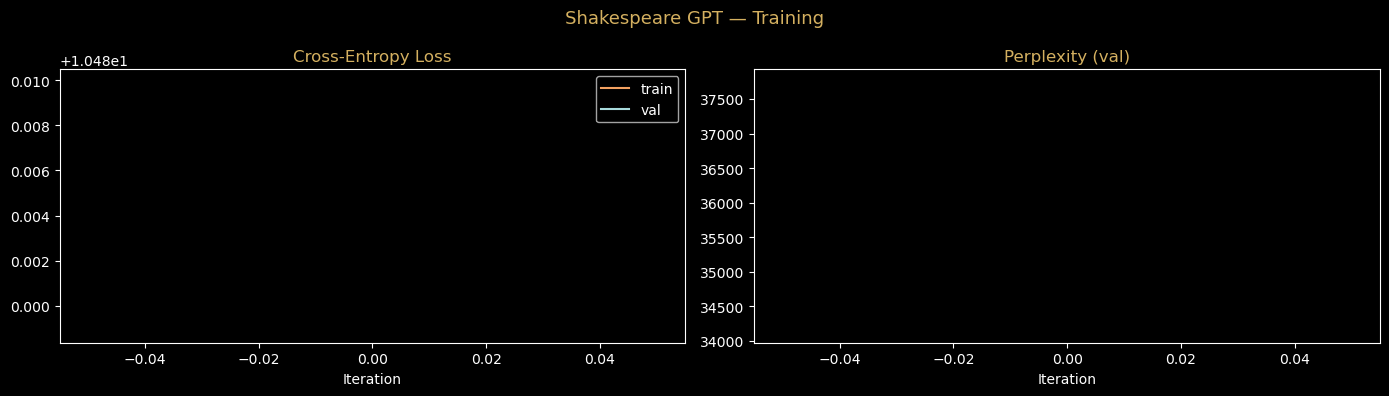

C:\Users\Rafael\AppData\Local\Temp\ipykernel_43428\472398291.py:93: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=cfg.use_amp):


iter   500 | train 5.1341 | val 5.7613 | ppl   317.8 | lr 4.99e-04 | 148s  💾 saved
iter  1000 | train 4.1580 | val 5.3059 | ppl   201.5 | lr 4.93e-04 | 147s  💾 saved
iter  1500 | train 3.4779 | val 5.2078 | ppl   182.7 | lr 4.81e-04 | 148s  💾 saved
iter  2000 | train 2.8975 | val 5.3755 | ppl   216.1 | lr 4.64e-04 | 147s
iter  2500 | train 2.3528 | val 5.5500 | ppl   257.2 | lr 4.42e-04 | 147s
iter  3000 | train 1.9350 | val 5.7293 | ppl   307.8 | lr 4.15e-04 | 147s
iter  3500 | train 1.5715 | val 5.9776 | ppl   394.5 | lr 3.85e-04 | 147s
iter  4000 | train 1.2569 | val 6.2338 | ppl   509.7 | lr 3.53e-04 | 148s
iter  4500 | train 1.0050 | val 6.4739 | ppl   648.0 | lr 3.18e-04 | 149s
iter  5000 | train 0.8324 | val 6.7181 | ppl   827.3 | lr 2.82e-04 | 150s
iter  5500 | train 0.6627 | val 6.8709 | ppl   963.8 | lr 2.46e-04 | 152s
iter  6000 | train 0.5506 | val 7.0387 | ppl  1139.9 | lr 2.11e-04 | 151s
iter  6500 | train 0.4634 | val 7.1955 | ppl  1333.4 | lr 1.77e-04 | 151s
iter  7000 

In [18]:
@torch.no_grad()
def estimate_loss(model, loader, eval_iters, use_amp):
    model.eval()
    losses = []
    for i, (x, y) in enumerate(loader):
        if i >= eval_iters:
            break
        x, y = x.to(device), y.to(device)
        with autocast(enabled=use_amp):
            _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))


# ── History ───────────────────────────────────────────────────────────────────
history = {'iter': [], 'train_loss': [], 'val_loss': [], 'lr': []}

# ── Live plot setup ───────────────────────────────────────────────────────────
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Shakespeare GPT — Training', fontsize=13, color='#d4b060')


def update_plot():
    iters = history['iter']
    for ax in axes:
        ax.cla()

    axes[0].plot(iters, history['train_loss'], label='train', color='#f4a261', lw=1.5)
    axes[0].plot(iters, history['val_loss'],   label='val',   color='#a8dadc', lw=1.5)
    axes[0].set_title('Cross-Entropy Loss', color='#d4b060')
    axes[0].set_xlabel('Iteration')
    axes[0].legend()
    if history['val_loss']:
        ppl = [math.exp(min(l, 20)) for l in history['val_loss']]
        axes[1].plot(iters, ppl, color='#e9c46a', lw=1.5)
    axes[1].set_title('Perplexity (val)', color='#d4b060')
    axes[1].set_xlabel('Iteration')
    fig.tight_layout()
    plt.pause(0.001)


# ── Training ──────────────────────────────────────────────────────────────────
train_iter = iter(train_loader)
model.train()
t0 = time.time()

print(f'Starting training for {cfg.max_iters} iterations …\n')

for it in tqdm(range(start_iter, cfg.max_iters), desc="Training"):

    # ── LR update ────────────────────────────────────────────────────────────
    lr = get_lr(it, cfg)
    for pg in optimizer.param_groups:
        pg['lr'] = lr

    # ── Eval ─────────────────────────────────────────────────────────────────
    if it % cfg.eval_interval == 0:
        t_loss = estimate_loss(model, train_loader, cfg.eval_iters, cfg.use_amp)
        v_loss = estimate_loss(model, val_loader,   cfg.eval_iters, cfg.use_amp)
        history['iter'].append(it)
        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['lr'].append(lr)

        marker = ''
        if v_loss < best_val_loss:
            best_val_loss = v_loss
            torch.save({
                'iter': it, 'model': model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'val_loss': v_loss, 'cfg': cfg
            }, Path(cfg.out_dir) / 'best.pt')
            marker = '  💾 saved'

        elapsed = time.time() - t0
        ppl     = math.exp(min(v_loss, 20))
        print(f'iter {it:>5} | train {t_loss:.4f} | val {v_loss:.4f} | ppl {ppl:>7.1f} | lr {lr:.2e} | {elapsed:.0f}s{marker}')
        update_plot()
        t0 = time.time()

    # ── Gradient accumulation ────────────────────────────────────────────────
    optimizer.zero_grad(set_to_none=True)
    for micro_step in range(cfg.grad_accum_steps):
        try:
            x, y = next(train_iter)
        except StopIteration:
            train_iter = iter(train_loader)
            x, y = next(train_iter)
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

        with autocast(enabled=cfg.use_amp):
            _, loss = model(x, y)
            loss    = loss / cfg.grad_accum_steps

        scaler.scale(loss).backward()

    scaler.unscale_(optimizer)
    nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
    scaler.step(optimizer)
    scaler.update()

print('\n✅ Training complete!')
plt.show()

## 10. Loss & Perplexity Summary

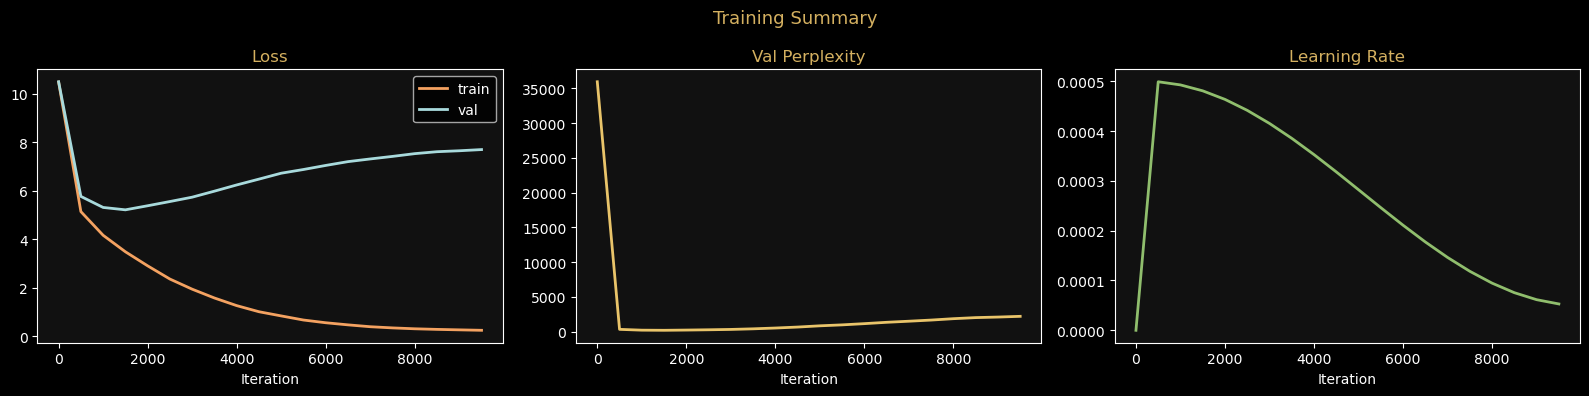

Best val loss : 5.2078  |  Perplexity : 182.7


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Training Summary', fontsize=13, color='#d4b060')

iters = history['iter']

axes[0].plot(iters, history['train_loss'], label='train', color='#f4a261', lw=2)
axes[0].plot(iters, history['val_loss'],   label='val',   color='#a8dadc', lw=2)
axes[0].set_title('Loss',        color='#d4b060')
axes[0].set_xlabel('Iteration'); axes[0].legend()

ppl = [math.exp(min(l, 20)) for l in history['val_loss']]
axes[1].plot(iters, ppl, color='#e9c46a', lw=2)
axes[1].set_title('Val Perplexity', color='#d4b060')
axes[1].set_xlabel('Iteration')

axes[2].plot(iters, history['lr'], color='#90be6d', lw=2)
axes[2].set_title('Learning Rate', color='#d4b060')
axes[2].set_xlabel('Iteration')

for ax in axes:
    ax.set_facecolor('#111')

fig.tight_layout()
fig.savefig('training_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Best val loss : {best_val_loss:.4f}  |  Perplexity : {math.exp(min(best_val_loss, 20)):.1f}')

## 11. Load Best Checkpoint & Generate

In [20]:
# Load best checkpoint
ckpt  = torch.load(Path(cfg.out_dir) / 'best.pt', map_location=device)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'✅ Loaded best checkpoint (iter {ckpt["iter"]}, val loss {ckpt["val_loss"]:.4f})')

C:\Users\Rafael\AppData\Local\Temp\ipykernel_43428\1581772190.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt  = torch.load(Path(cfg.out_dir) / 'best.pt', map_locat

✅ Loaded best checkpoint (iter 1500, val loss 5.2078)


In [21]:
# ── Generation settings ───────────────────────────────────────────────────────
SEED        = "The history of artificial intelligence began with"       # change to any seed
MAX_NEW     = 500
TEMPERATURE = 0.8               # 0.6 = conservative, 1.0 = wild
TOP_K       = 40                # top-k sampling
TOP_P       = 0.95              # nucleus (top-p) sampling

# ── Encode seed ───────────────────────────────────────────────────────────────
context = torch.tensor(encode(SEED), dtype=torch.long, device=device).unsqueeze(0)

with torch.no_grad():
    out = model.generate(context, MAX_NEW, temperature=TEMPERATURE, top_k=TOP_K, top_p=TOP_P)

generated = decode(out[0].tolist())
print('─' * 70)
print(generated)
print('─' * 70)

──────────────────────────────────────────────────────────────────────
The history of artificial intelligence began with the " light " of the artificial intelligence . = = = The AI program = = = = The AI research has been widely debated . The first developed for the early 80s , first , then the earliest developed AI research in the early 1970s , the second generation of AI research . The program of AI research on AI research had been developed in the early 1980s . The major research in which had been developed by Samuel Taylor and his followers 's American researchers were often subject to the idea of a simple idea that it needed a new model for many different types of artificial intelligence . They also suggested that it could be solved in artificial intelligence : " I think it 's a serious idea . " Minsky was a natural theory that was the natural and that a machine would have a machine to reach of its artificial intelligence . " Minsky said that " an idea of an individual 's research

In [22]:
# ── Multi-seed batch generation ───────────────────────────────────────────────
seeds = [
    "The history of artificial intelligence began with",
    "Water is a state",
    "The Romans are believed to be",
]

for seed in seeds:
    ctx = torch.tensor(encode(seed), dtype=torch.long, device=device).unsqueeze(0)
    with torch.no_grad():
        out = model.generate(ctx, 200, temperature=TEMPERATURE, top_k=TOP_K)
    print(f'\n──[ Seed: {seed!r} ]{'─'*(50-len(seed))}')
    print(decode(out[0].tolist()))


──[ Seed: 'The history of artificial intelligence began with' ]─
The history of artificial intelligence began with the artificial intelligence , as a process . = = = Stasp = = A program of artificial intelligence was developed during the 1940s , as researchers began to increase artificial intelligence . The use of intelligence for artificial intelligence as a machine could be justified in the field . They began to begin a general approach to be sufficient for a well @-@ developed human intelligence . The program was a very well @-@ sufficient number of large intelligence , and all ideas were made . A few short @-@ term intelligence applications were developed . The idea of a program of a large robotics was to develop and prevent the possibility of a large number of intelligence . But many of computers came to solve problems , such as an attempt of researchers could affect the number of intelligence as a computer science . Through the late 1940s and 1940s , the general intelligence was

## 12. Model Inspector

In [23]:
print(f'{'─'*50}')
print(f'  Model Architecture Summary')
print(f'{'─'*50}')
print(f'  Vocabulary size  : {cfg.vocab_size}')
print(f'  Context window   : {cfg.block_size} tokens')
print(f'  Layers           : {cfg.n_layer}')
print(f'  Attention heads  : {cfg.n_head}')
print(f'  Embedding dim    : {cfg.n_embd}')
print(f'  Total params     : {model.num_params()/1e6:.2f} M')
print(f'  Dropout          : {cfg.dropout}')
print(f'  Weight tying     : Yes (wte ↔ lm_head)')
print(f'  Flash Attention  : {model.transformer["h"][0].attn.flash}')
print(f'  Mixed Precision  : {cfg.use_amp}')
print(f'{'─'*50}')

# Param breakdown
for name, p in model.named_parameters():
    if p.requires_grad:
        print(f'  {name:<45} {list(p.shape)}')

──────────────────────────────────────────────────
  Model Architecture Summary
──────────────────────────────────────────────────
  Vocabulary size  : 33000
  Context window   : 256 tokens
  Layers           : 6
  Attention heads  : 8
  Embedding dim    : 512
  Total params     : 35.91 M
  Dropout          : 0.1
  Weight tying     : Yes (wte ↔ lm_head)
  Flash Attention  : True
  Mixed Precision  : True
──────────────────────────────────────────────────
  transformer.wte.weight                        [33000, 512]
  transformer.wpe.weight                        [256, 512]
  transformer.h.0.ln1.weight                    [512]
  transformer.h.0.ln1.bias                      [512]
  transformer.h.0.attn.c_attn.weight            [1536, 512]
  transformer.h.0.attn.c_proj.weight            [512, 512]
  transformer.h.0.ln2.weight                    [512]
  transformer.h.0.ln2.bias                      [512]
  transformer.h.0.mlp.net.0.weight              [2048, 512]
  transformer.h.0.mlp.net.

## 13. Tips for Your RTX 4060

| Goal | Tweak |
|------|-------|
| **Fit more in VRAM** | Reduce `batch_size` → 32 or `block_size` → 128 |
| **Bigger model (~85M params)** | `n_layer=12, n_head=12, n_embd=768` |
| **Faster training** | Set `cfg.compile = True` (PyTorch 2.0+) |
| **More creative output** | Raise `TEMPERATURE` to 1.0–1.2 |
| **More coherent output** | Lower temperature, lower top_k |
| **Full Shakespeare corpus** | Download Project Gutenberg's complete works |
| **Fine-tune GPT-2** | Use HuggingFace `transformers.GPT2LMHeadModel` + `Trainer` |